In [1]:
import sys; sys.path.append("..")
import numpy as np, pandas as pd, mne
from mne.time_frequency import psd_array_welch
from src.load import list_subjects, load_subject
from src.channels import CHANNELS, SFREQ

N = 4 * SFREQ                         # samples per 4 s window = 512
windows, subject, label = [], [], []
for _, k in pd.DataFrame(list_subjects()).iterrows():
    x = mne.filter.filter_data(load_subject(k.path), SFREQ, 1.0, 40.0, verbose=False)
    x = x[:, :60 * SFREQ]                               # keep the first 60 s only
    windows.append(x.reshape(19, 15, N).transpose(1, 0, 2))   # -> (15 windows, 19 ch, 512)
    subject += [k.subject_id] * 15
    label += [k.label] * 15

W = np.concatenate(windows)           # all windows: (1815, 19, 512)
subject, label = np.array(subject), np.array(label)
print(W.shape)

(1815, 19, 512)


In [2]:
psd, freqs = psd_array_welch(W, SFREQ, fmin=1, fmax=40, n_fft=N, verbose=False)
print(psd.shape)                      # (1815 windows, 19 channels, n frequencies)

def band(lo, hi):
    """Power between lo and hi Hz, for every window and channel -> (1815, 19)."""
    return psd[..., (freqs >= lo) & (freqs < hi)].sum(axis=-1)

(1815, 19, 157)


In [3]:
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold

theta, alpha, beta = band(4, 8), band(8, 13), band(13, 30)
total_1_40 = band(1, 41)
A = np.hstack([theta/total_1_40, alpha/total_1_40, beta/total_1_40, theta/beta])
names = [f"{b}_{ch}" for b in ["theta", "alpha", "beta", "tbr"] for ch in CHANNELS]
print(A.shape, len(names))      # (1815, 76) 76

(1815, 76) 76


In [4]:
def test_shap(cv):
    """Train on 4 folds, explain the held-out fold. Repeat for all 5 folds."""
    S = np.zeros(A.shape)
    for train, test in cv.split(A, label, groups=subject):
        model = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=42)
        model.fit(A[train], label[train])
        sv = shap.TreeExplainer(model).shap_values(A[test])
        if isinstance(sv, list): sv = sv[1]          # older shap: [control, ADHD]
        elif sv.ndim == 3:       sv = sv[..., 1]     # newer shap: (windows, features, 2)
        S[test] = sv                                 # keep the "towards ADHD" part
    return S

S_honest = test_shap(StratifiedGroupKFold(5, shuffle=True, random_state=0))   # split by subject
S_cheat  = test_shap(StratifiedKFold(5, shuffle=True, random_state=0))        # windows shuffled
print("done")

c:\Users\Rajesh Sampathkumar\miniconda3\envs\medimg\Lib\site-packages\sklearn\model_selection\_split.py:884: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


done


In [5]:
imp = pd.DataFrame({"honest": np.abs(S_honest).mean(axis=0),
                    "cheat":  np.abs(S_cheat).mean(axis=0)}, index=names)
imp = imp / imp.sum()                     # each feature's share of the total credit

print("HONEST top 10\n", imp.sort_values("honest", ascending=False).head(10).round(3))
print("\nCHEAT top 10\n", imp.sort_values("cheat", ascending=False).head(10).round(3))

for col in ["honest", "cheat"]:
    n50 = (imp[col].sort_values(ascending=False).cumsum() < 0.5).sum() + 1
    print(f"{col}: {n50} features hold half of all the credit")

HONEST top 10
            honest  cheat
beta_Pz     0.051  0.057
tbr_P7      0.045  0.046
alpha_O1    0.043  0.044
beta_T8     0.036  0.038
beta_P8     0.033  0.034
alpha_Fp2   0.032  0.030
tbr_T7      0.031  0.030
tbr_Pz      0.031  0.036
beta_T7     0.026  0.027
beta_P7     0.023  0.023

CHEAT top 10
            honest  cheat
beta_Pz     0.051  0.057
tbr_P7      0.045  0.046
alpha_O1    0.043  0.044
beta_T8     0.036  0.038
tbr_Pz      0.031  0.036
beta_P8     0.033  0.034
alpha_Fp2   0.032  0.030
tbr_T7      0.031  0.030
beta_T7     0.026  0.027
beta_P3     0.020  0.026
honest: 19 features hold half of all the credit
cheat: 18 features hold half of all the credit


In [ ]:
from scipy.stats import spearmanr

# How similar are the SHAP feature rankings of the leaky vs the honest model?
rho = spearmanr(imp["honest"], imp["cheat"]).correlation
print(f"SHAP honest-vs-cheat ranking Spearman rho = {rho:.3f}")   # ~1 -> SHAP is blind to the leak

C:\Users\Rajesh Sampathkumar\AppData\Local\Temp\ipykernel_9732\1031905223.py:2: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  info = mne.create_info(CHANNELS, SFREQ, "eeg"); info.set_montage("standard_1020")


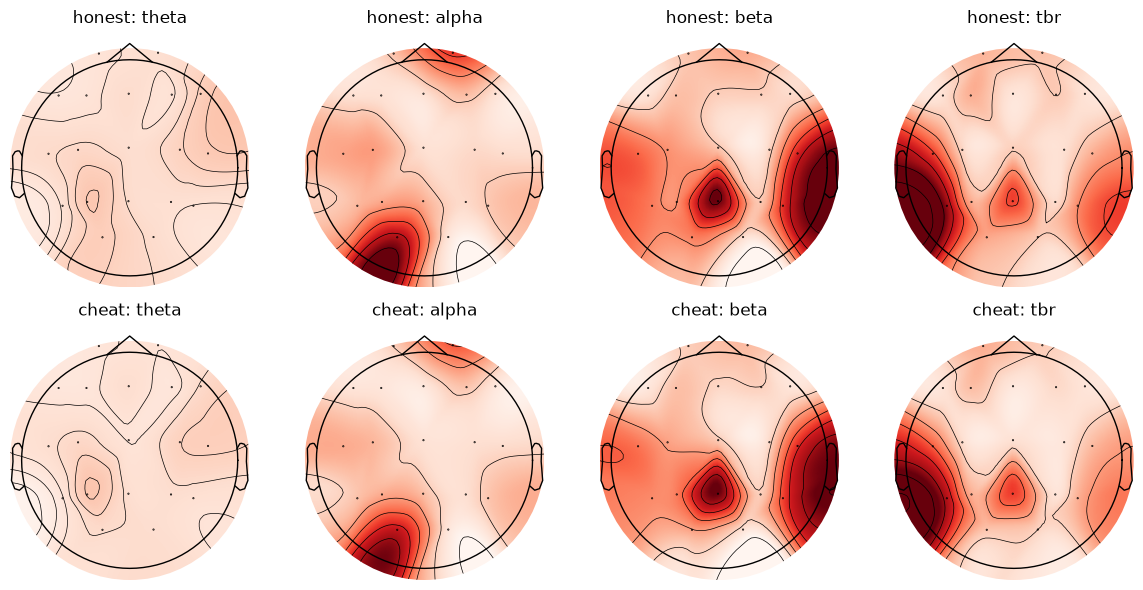

In [6]:
import matplotlib.pyplot as plt
info = mne.create_info(CHANNELS, SFREQ, "eeg"); info.set_montage("standard_1020")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for r, col in enumerate(["honest", "cheat"]):
    vals = imp[col].values.reshape(4, 19)          # rows: theta, alpha, beta, tbr
    for c, b in enumerate(["theta", "alpha", "beta", "tbr"]):
        mne.viz.plot_topomap(vals[c], info, axes=axes[r, c], show=False, vlim=(0, vals.max()))
        axes[r, c].set_title(f"{col}: {b}")
plt.tight_layout()

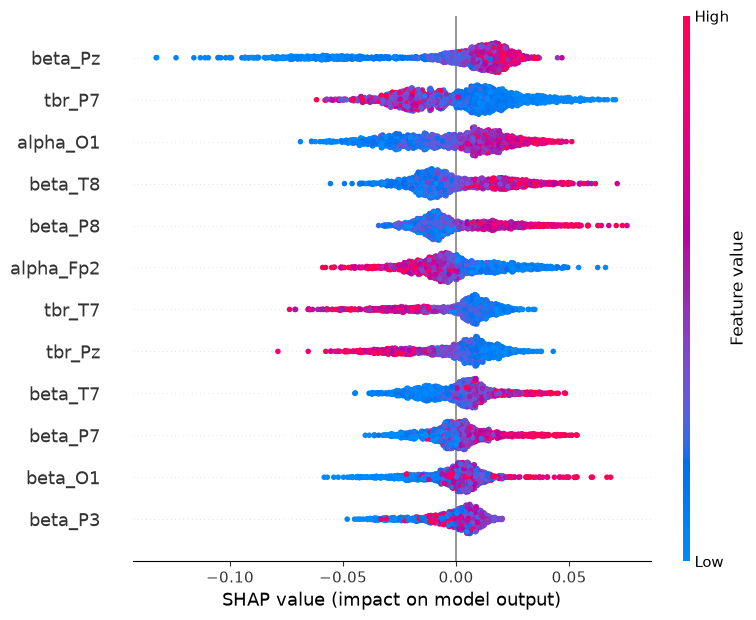

In [7]:
shap.summary_plot(S_honest, A, feature_names=names, max_display=12)

In [9]:
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier

def perm_imp(cv):
    """AUC drop per feature when it is scrambled on the held-out fold, averaged over folds."""
    P = np.zeros(A.shape[1])                                   # one score per feature (76)
    for train, test in cv.split(A, label, groups=subject):
        model = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=42)
        model.fit(A[train], label[train])
        r = permutation_importance(model, A[test], label[test],
                                   n_repeats=5, scoring="roc_auc", random_state=42)
        P += r.importances_mean                                # AUC drop per feature, this fold
    return P / cv.get_n_splits()                               # average over the folds

In [10]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from scipy.stats import spearmanr

rows = []
for seed in range(5):
    P_seg = perm_imp(StratifiedKFold(5, shuffle=True, random_state=seed))
    P_sub = perm_imp(StratifiedGroupKFold(5, shuffle=True, random_state=seed))
    rows.append({"seed": seed,
                 "drop_segwise": P_seg.sum(),
                 "drop_subwise": P_sub.sum(),
                 "ratio": P_seg.sum() / P_sub.sum(),
                 "spearman": spearmanr(P_seg, P_sub).correlation})
    print(rows[-1])

res = pd.DataFrame(rows)
print(res.round(3))
print(res[["drop_segwise", "drop_subwise", "ratio", "spearman"]].agg(["mean", "std"]).round(3))

c:\Users\Rajesh Sampathkumar\miniconda3\envs\medimg\Lib\site-packages\sklearn\model_selection\_split.py:884: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


{'seed': 0, 'drop_segwise': np.float64(0.21153551912568355), 'drop_subwise': np.float64(0.08020166191832492), 'ratio': np.float64(2.637545333425949), 'spearman': np.float64(0.6191293173713831)}


c:\Users\Rajesh Sampathkumar\miniconda3\envs\medimg\Lib\site-packages\sklearn\model_selection\_split.py:884: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


{'seed': 1, 'drop_segwise': np.float64(0.19001700060716314), 'drop_subwise': np.float64(0.05350707502373895), 'ratio': np.float64(3.5512500080196907), 'spearman': np.float64(0.5149965823650035)}


c:\Users\Rajesh Sampathkumar\miniconda3\envs\medimg\Lib\site-packages\sklearn\model_selection\_split.py:884: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


{'seed': 2, 'drop_segwise': np.float64(0.20207225258045175), 'drop_subwise': np.float64(0.057923741690409106), 'ratio': np.float64(3.488591149040195), 'spearman': np.float64(0.4836363636363637)}


c:\Users\Rajesh Sampathkumar\miniconda3\envs\medimg\Lib\site-packages\sklearn\model_selection\_split.py:884: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


{'seed': 3, 'drop_segwise': np.float64(0.20721432908317736), 'drop_subwise': np.float64(0.07305593542259817), 'ratio': np.float64(2.8363791098495796), 'spearman': np.float64(0.6691455912508544)}


c:\Users\Rajesh Sampathkumar\miniconda3\envs\medimg\Lib\site-packages\sklearn\model_selection\_split.py:884: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


{'seed': 4, 'drop_segwise': np.float64(0.188825743776565), 'drop_subwise': np.float64(0.03945246913580101), 'ratio': np.float64(4.786157822634622), 'spearman': np.float64(0.40155844155844156)}
   seed  drop_segwise  drop_subwise  ratio  spearman
0     0         0.212         0.080  2.638     0.619
1     1         0.190         0.054  3.551     0.515
2     2         0.202         0.058  3.489     0.484
3     3         0.207         0.073  2.836     0.669
4     4         0.189         0.039  4.786     0.402
      drop_segwise  drop_subwise  ratio  spearman
mean          0.20         0.061  3.460     0.538
std           0.01         0.016  0.842     0.107
